In [1]:
# Collect the data
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Path to dataset files: /home/sudipto/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1


In [ ]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


In [15]:

DATASET_PATH = os.path.join(path, 'WA_Fn-UseC_-Telco-Customer-Churn.csv')

df = pd.read_csv(DATASET_PATH)

In [44]:

ROOT_DIR = os.path.dirname(os.getcwd())

DATA_DIR = os.path.join(ROOT_DIR, 'data')
DATA_DIR_RAW = os.path.join(DATA_DIR, 'raw')
DATA_DIR_PROCESSED = os.path.join(DATA_DIR, 'processed')

DATASET_NAME_V1 = f"{DATA_DIR_RAW}/churnv1.csv"

# df.to_csv(DATASET_NAME_V1, index=True)



#### Load the dataset

In [45]:
df = pd.read_csv(DATASET_NAME_V1)

df.sample(5)

,Unnamed: 0,index,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
5904,5904,5904,9402-CXWPL,Female,0,No,No,70,Yes,Yes,...,No,No,Yes,Yes,One year,No,Electronic check,98.90,6838.6,No
504,504,504,5736-YEJAX,Male,0,No,Yes,69,Yes,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Credit card (automatic),79.45,5502.55,No
1524,1524,1524,1656-DRSMG,Female,0,No,No,63,Yes,Yes,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),109.85,7002.95,No
6551,6551,6551,6728-VOIFY,Female,0,Yes,No,63,Yes,No,...,No,No,Yes,Yes,One year,Yes,Electronic check,96.00,6109.75,No
6434,6434,6434,6608-QQLVK,Male,0,No,No,1,Yes,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,50.50,50.5,Yes


#### Dataset info

In [81]:
# df = df.rename(columns={'Inedx': 'Index'})
# df.drop(columns=['Unnamed: 0'], inplace=True)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             7043 non-null   int64  
 1   customerID        7043 non-null   object 
 2   gender            7043 non-null   object 
 3   SeniorCitizen     7043 non-null   int64  
 4   Partner           7043 non-null   object 
 5   Dependents        7043 non-null   object 
 6   tenure            7043 non-null   int64  
 7   PhoneService      7043 non-null   object 
 8   MultipleLines     7043 non-null   object 
 9   InternetService   7043 non-null   object 
 10  OnlineSecurity    7043 non-null   object 
 11  OnlineBackup      7043 non-null   object 
 12  DeviceProtection  7043 non-null   object 
 13  TechSupport       7043 non-null   object 
 14  StreamingTV       7043 non-null   object 
 15  StreamingMovies   7043 non-null   object 
 16  Contract          7043 non-null   object 


### Data Exploration

### Target 

__Churn__ Column is our target column and here we need to find the customer/individual who can leave service within a specific period of time.

>__Churn prediction is the use of data, statistics, and machine learning to forecast which customers or subscribers are likely to stop using a product or cancel a service within a specific time frame__

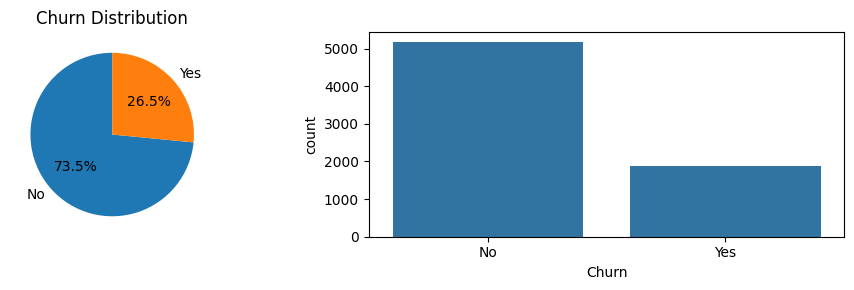

In [64]:
churn_counts = df['Churn'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].pie(churn_counts, 
            labels=churn_counts.index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0].set_title('Churn Distribution')

sns.countplot(data=df, x='Churn', ax=axes[1])
fig.tight_layout()
plt.show()

__Separate Feature and target columns from the dataset__

In [71]:
features = df.drop(columns=['Churn', 'index', 'customerID'])
target = df['Churn']

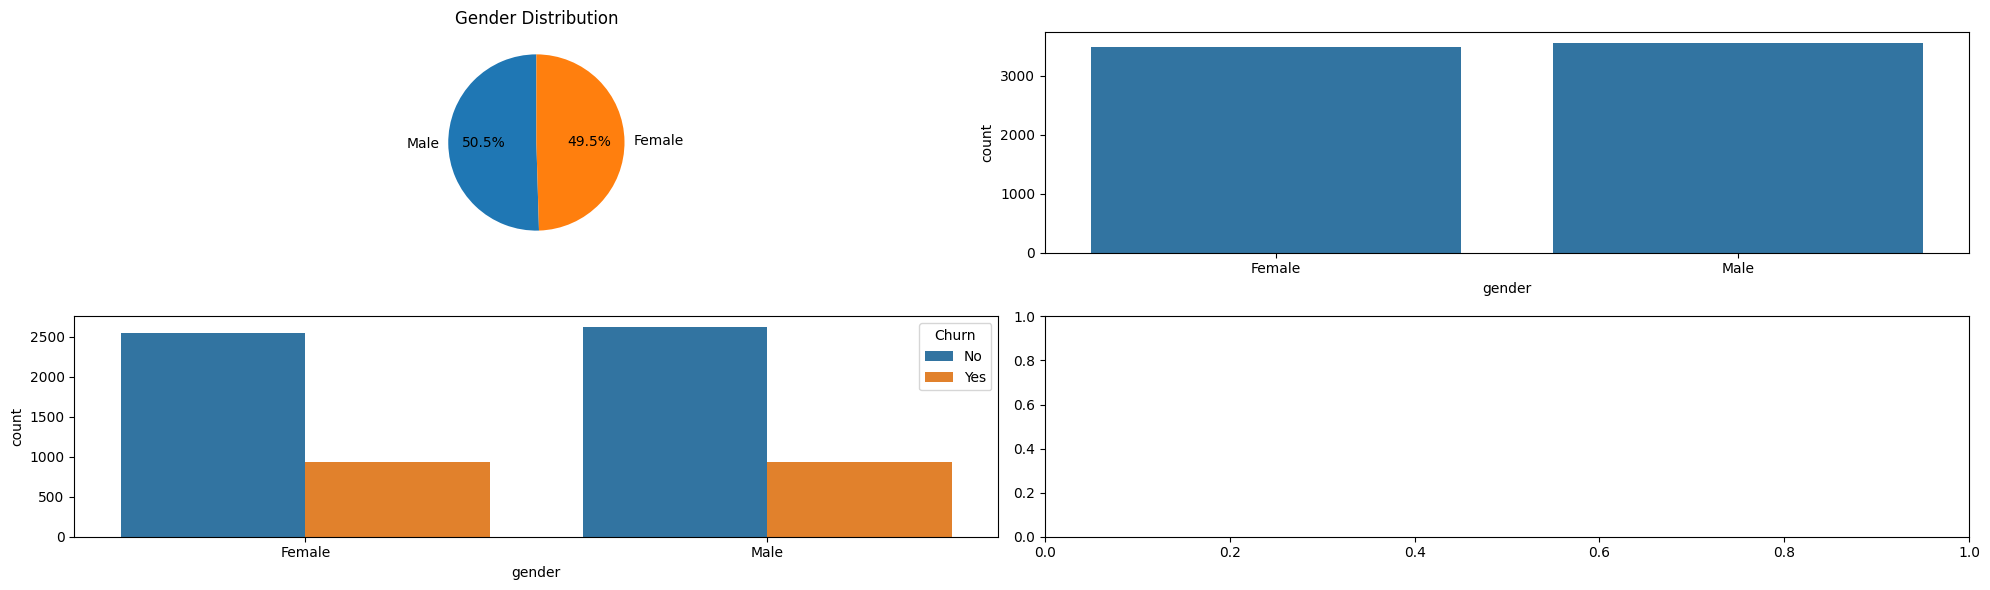

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['gender'].value_counts(), 
            labels=features['gender'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('Gender Distribution')

sns.countplot(data=features, x='gender', ax=axes[0, 1])
sns.countplot(data=features, x='gender', hue=target, ax=axes[1, 0])

fig.tight_layout()

plt.show()

__We have 50.5% of male and 49.5% of female here and in counts there are 3555 male and 3488 female customers.__

In [88]:
print(features['SeniorCitizen'].value_counts())

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


In `SeniorCitizen` columns we have only value 0 and 1. That means `boolean` value is that this __individual__ is __SeniorCitizen__ or not.

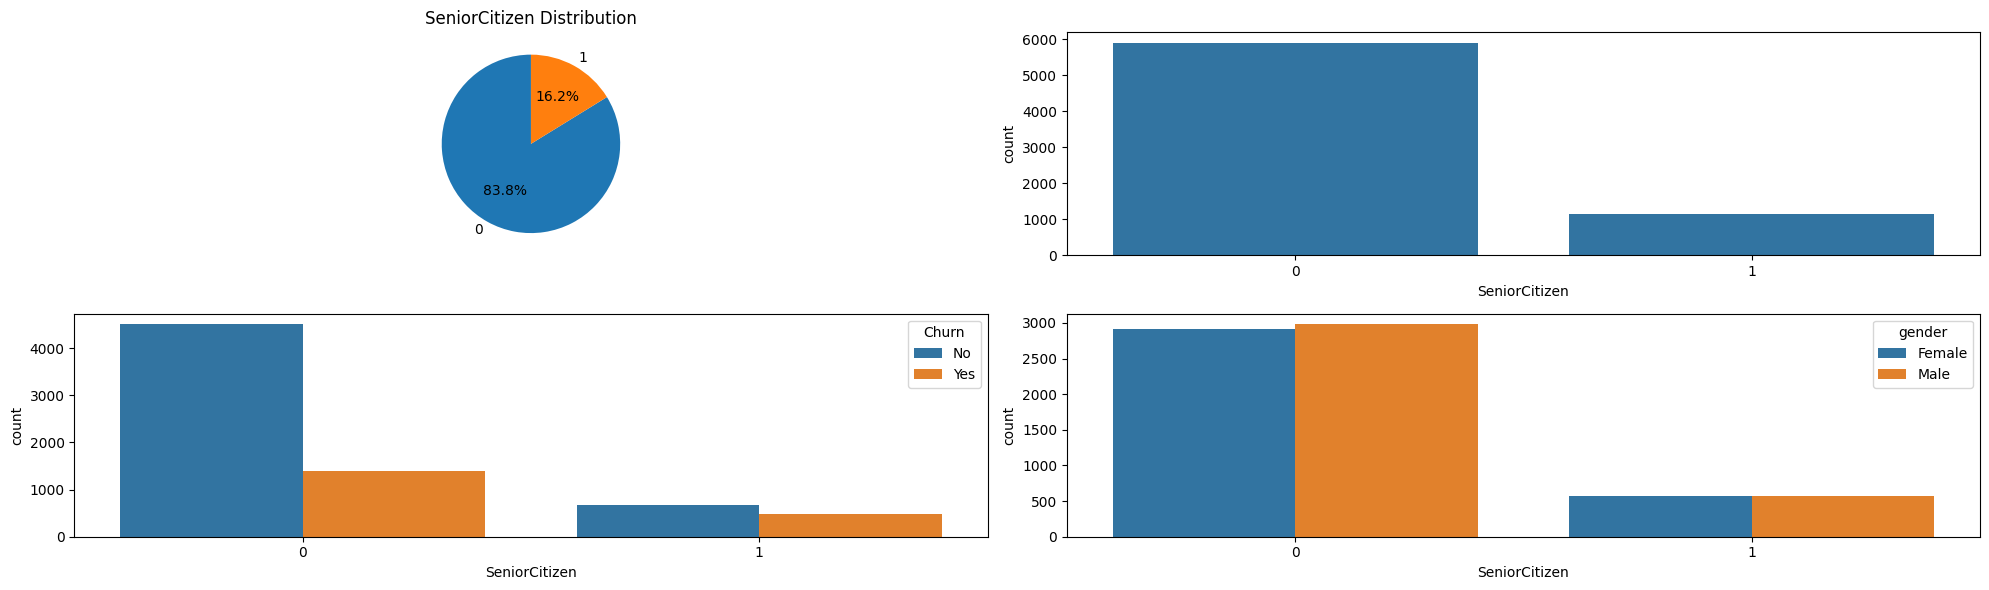

In [93]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['SeniorCitizen'].value_counts(), 
            labels=features['SeniorCitizen'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('SeniorCitizen Distribution')

sns.countplot(data=features, x='SeniorCitizen', ax=axes[0, 1])
sns.countplot(data=features, x='SeniorCitizen', hue=target, ax=axes[1, 0])
sns.countplot(data=features, x='SeniorCitizen', hue='gender', ax=axes[1, 1])


fig.tight_layout()

plt.show()

In [96]:
features['Partner'].unique()

array(['Yes', 'No'], dtype=object)